DATASET GENERATED SUCCESSFULLY
          H2        CH4       C2H2       C2H4       C2H6          CO  \
0  59.493851  19.055195  12.544422  25.562097  18.426293  184.263985   
1  65.406730  16.969477  12.091239  12.754116  16.991732  217.675226   
2  27.338659  16.427087   7.015305  16.743946  14.554844  121.998783   
3  46.200993  20.478328   6.073428  12.397765  20.791727  133.682771   
4  40.520153  18.058915   8.101002  28.684232  19.905742  138.119402   
5  32.613546  21.516811   5.036445   9.423298  21.426612  258.987726   
6  48.016567  17.999536   5.960190  11.659307  17.022035  289.544832   
7  26.976307  22.402256   8.739092  11.835784  24.774601  286.909605   
8  37.274031  17.948525  11.229310  21.104599  16.911964  187.417121   
9  32.895987  26.578864  16.075062  14.626671  28.416467  226.986371   

           CO2 Fault_Type  
0  3475.963358     Normal  
1  1023.777374     Normal  
2  3340.512538     Normal  
3  2281.062828     Normal  
4  2667.223116     Normal  
5  2123.

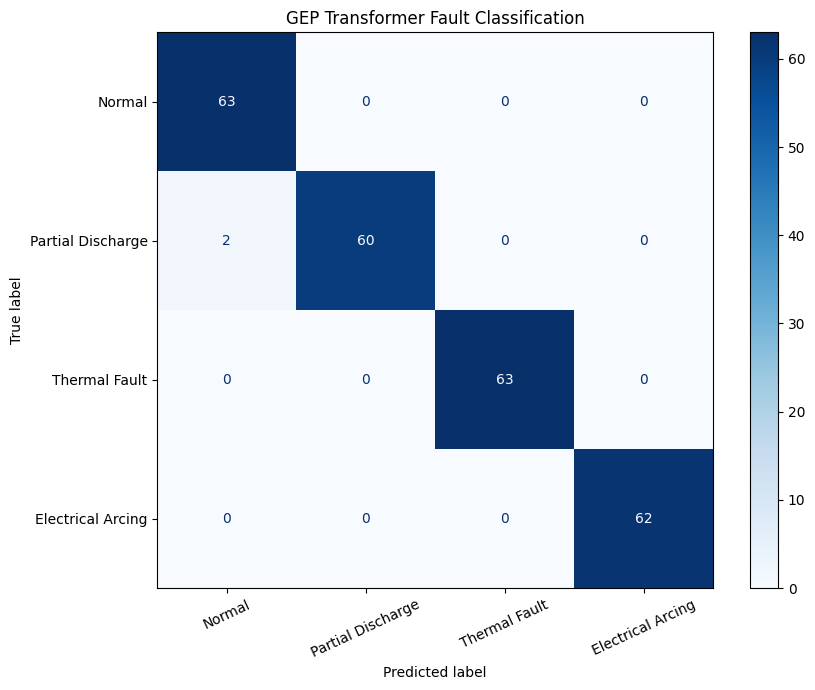

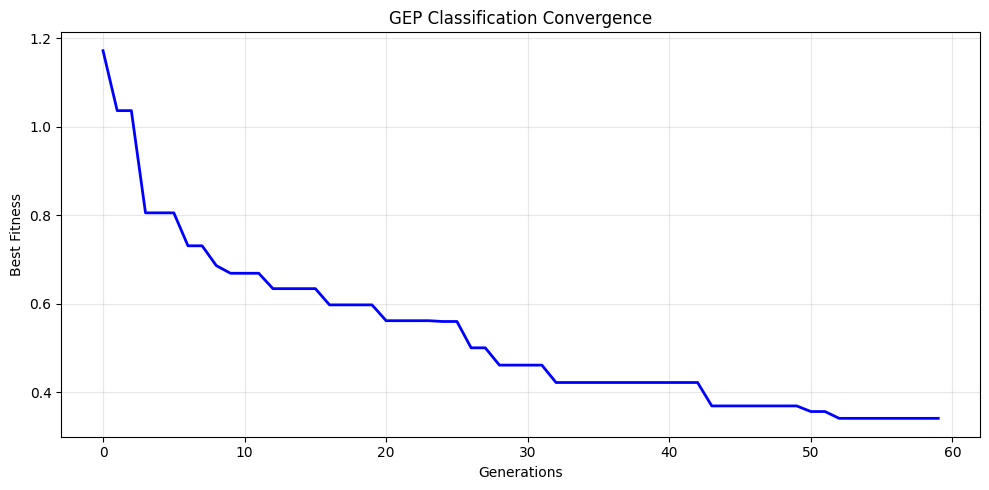


ACTUAL VS PREDICTED RESULTS
     Actual Fault   Predicted Fault  Correct Prediction
    Thermal Fault     Thermal Fault                True
Partial Discharge Partial Discharge                True
    Thermal Fault     Thermal Fault                True
Partial Discharge Partial Discharge                True
           Normal            Normal                True
Partial Discharge Partial Discharge                True
    Thermal Fault     Thermal Fault                True
           Normal            Normal                True
Electrical Arcing Electrical Arcing                True
           Normal            Normal                True
    Thermal Fault     Thermal Fault                True
Partial Discharge Partial Discharge                True
Electrical Arcing Electrical Arcing                True
Partial Discharge Partial Discharge                True
Partial Discharge Partial Discharge                True
           Normal            Normal                True
           Normal  

In [1]:
# ============================================================
# POWER TRANSFORMER FAULT DIAGNOSIS USING GEP
# Gene Expression Programming - Google Colab
#
# Input: Seven Dissolved Gas Analysis (DGA) measurements
# Output: Four transformer fault categories
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import copy

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Reproducibility
np.random.seed(42)
random.seed(42)

# ============================================================
# 1. GENERATE SYNTHETIC TRANSFORMER DGA DATASET
# ============================================================

gas_names = [
    "H2", "CH4", "C2H2", "C2H4",
    "C2H6", "CO", "CO2"
]

class_names = [
    "Normal",
    "Partial Discharge",
    "Thermal Fault",
    "Electrical Arcing"
]

# Illustrative median gas profiles in ppm.
# These are synthetic demonstration profiles, not
# validated diagnostic thresholds.

gas_profiles = np.array([
    [50, 20, 10, 15, 20, 200, 2000],
    [300, 20, 5, 10, 5, 100, 1000],
    [100, 150, 20, 250, 100, 500, 3000],
    [500, 100, 300, 200, 50, 200, 1500]
], dtype=float)

samples_per_class = 250

X_data = []
y_data = []

for class_id in range(4):

    # Generate positive gas concentrations
    samples = np.random.lognormal(
        mean=np.log(gas_profiles[class_id]),
        sigma=0.35,
        size=(samples_per_class, 7)
    )

    X_data.append(samples)
    y_data.extend([class_id] * samples_per_class)

X_data = np.vstack(X_data)
y_data = np.array(y_data)

# Create dataframe
df = pd.DataFrame(X_data, columns=gas_names)

df["Fault_Type"] = [
    class_names[i] for i in y_data
]

print("DATASET GENERATED SUCCESSFULLY")
print("=" * 55)

print(df.head(10))

print("\nDataset shape:", df.shape)

print("\nClass distribution:")
print(df["Fault_Type"].value_counts())

# ============================================================
# 2. DATA PREPROCESSING
# ============================================================

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_data,
    y_data,
    test_size=0.25,
    random_state=42,
    stratify=y_data
)

# Log transformation reduces concentration skew
X_train = np.log1p(X_train)
X_test = np.log1p(X_test)

# Standardization
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

# ============================================================
# 3. GEP PARAMETERS
# ============================================================

NUM_CLASSES = 4

POPULATION_SIZE = 60
GENERATIONS = 60

HEAD_LENGTH = 8
TAIL_LENGTH = HEAD_LENGTH + 1
GENE_LENGTH = HEAD_LENGTH + TAIL_LENGTH

MUTATION_RATE = 0.04
CROSSOVER_RATE = 0.70

ELITE_SIZE = 2
TOURNAMENT_SIZE = 3

# Function symbols and arity
FUNCTIONS = {
    "+": 2,
    "-": 2,
    "*": 2,
    "/": 2
}

TERMINALS = (
    [f"X{i}" for i in range(7)]
    + ["0", "1", "-1", "0.5", "2"]
)

HEAD_SYMBOLS = list(FUNCTIONS.keys()) + TERMINALS

# ============================================================
# 4. CREATE GEP GENES
# ============================================================

def create_gene():

    head = [
        random.choice(HEAD_SYMBOLS)
        for _ in range(HEAD_LENGTH)
    ]

    tail = [
        random.choice(TERMINALS)
        for _ in range(TAIL_LENGTH)
    ]

    return head + tail


def create_chromosome():

    return [
        create_gene()
        for _ in range(NUM_CLASSES)
    ]


# ============================================================
# 5. GENE EXPRESSION / DECODING
# ============================================================

def decode_gene(gene):

    expression = []
    required = 1

    for symbol in gene:

        expression.append(symbol)

        required += FUNCTIONS.get(symbol, 0) - 1

        if required == 0:
            break

    return expression


# ============================================================
# 6. EVALUATE GEP EXPRESSION
# ============================================================

def evaluate_expression(expression, X):

    index = [0]

    def evaluate():

        if index[0] >= len(expression):
            return np.zeros(len(X))

        symbol = expression[index[0]]
        index[0] += 1

        # Input variable
        if symbol.startswith("X"):

            feature_index = int(symbol[1:])
            return X[:, feature_index]

        # Constants
        if symbol in ["0", "1", "-1", "0.5", "2"]:
            return np.full(len(X), float(symbol))

        # Binary operators
        a = evaluate()
        b = evaluate()

        if symbol == "+":
            result = a + b

        elif symbol == "-":
            result = a - b

        elif symbol == "*":
            result = a * b

        elif symbol == "/":
            result = a / np.where(
                np.abs(b) < 0.01,
                0.01,
                b
            )

        else:
            result = np.zeros(len(X))

        return np.clip(result, -20, 20)

    try:

        return np.nan_to_num(
            evaluate(),
            nan=0,
            posinf=20,
            neginf=-20
        )

    except (ValueError, OverflowError, RecursionError):

        return np.zeros(len(X))


# ============================================================
# 7. CHROMOSOME PREDICTION
# ============================================================

def predict_scores(chromosome, X):

    scores = []

    for gene in chromosome:

        expression = decode_gene(gene)

        score = evaluate_expression(expression, X)

        scores.append(score)

    return np.column_stack(scores)


def softmax(scores):

    scores = scores - np.max(
        scores, axis=1, keepdims=True
    )

    exp_scores = np.exp(scores)

    return exp_scores / (
        np.sum(exp_scores, axis=1, keepdims=True)
        + 1e-12
    )


# ============================================================
# 8. FITNESS FUNCTION
# ============================================================

def fitness_function(chromosome, X, y):

    scores = predict_scores(chromosome, X)

    probabilities = softmax(scores)

    # Multi-class cross entropy
    correct_probabilities = probabilities[
        np.arange(len(y)), y
    ]

    loss = -np.mean(
        np.log(correct_probabilities + 1e-12)
    )

    predictions = np.argmax(scores, axis=1)

    accuracy = np.mean(predictions == y)

    # Minimize classification error and prediction loss
    fitness = loss + 0.2 * (1 - accuracy)

    return fitness


# ============================================================
# 9. TOURNAMENT SELECTION
# ============================================================

def tournament_selection(population, fitness):

    candidates = random.sample(
        range(len(population)),
        TOURNAMENT_SIZE
    )

    winner = min(
        candidates,
        key=lambda i: fitness[i]
    )

    return copy.deepcopy(population[winner])


# ============================================================
# 10. MUTATION
# ============================================================

def mutation(chromosome):

    child = copy.deepcopy(chromosome)

    for gene in child:

        for i in range(GENE_LENGTH):

            if random.random() < MUTATION_RATE:

                if i < HEAD_LENGTH:

                    gene[i] = random.choice(
                        HEAD_SYMBOLS
                    )

                else:

                    gene[i] = random.choice(
                        TERMINALS
                    )

    return child


# ============================================================
# 11. RECOMBINATION / CROSSOVER
# ============================================================

def crossover(parent1, parent2):

    child1 = copy.deepcopy(parent1)
    child2 = copy.deepcopy(parent2)

    if random.random() < CROSSOVER_RATE:

        for gene_index in range(NUM_CLASSES):

            # Crossover head
            point = random.randint(
                1, HEAD_LENGTH - 1
            )

            g1 = child1[gene_index]
            g2 = child2[gene_index]

            g1[:point], g2[:point] = (
                g2[:point],
                g1[:point]
            )

            # Crossover tail
            point = random.randint(
                HEAD_LENGTH + 1,
                GENE_LENGTH - 1
            )

            g1[point:], g2[point:] = (
                g2[point:],
                g1[point:]
            )

    return child1, child2


# ============================================================
# 12. MAIN GEP CLASSIFICATION ALGORITHM
# ============================================================

def GEP_classifier(X, y):

    population = [
        create_chromosome()
        for _ in range(POPULATION_SIZE)
    ]

    best_chromosome = None
    best_fitness = float("inf")

    history = []

    for generation in range(GENERATIONS):

        fitness = np.array([
            fitness_function(individual, X, y)
            for individual in population
        ])

        best_index = np.argmin(fitness)

        if fitness[best_index] < best_fitness:

            best_fitness = fitness[best_index]

            best_chromosome = copy.deepcopy(
                population[best_index]
            )

        history.append(best_fitness)

        # Sort population
        sorted_indices = np.argsort(fitness)

        # Elitism
        new_population = [
            copy.deepcopy(population[i])
            for i in sorted_indices[:ELITE_SIZE]
        ]

        # Generate offspring
        while len(new_population) < POPULATION_SIZE:

            parent1 = tournament_selection(
                population, fitness
            )

            parent2 = tournament_selection(
                population, fitness
            )

            child1, child2 = crossover(
                parent1, parent2
            )

            child1 = mutation(child1)
            child2 = mutation(child2)

            new_population.append(child1)

            if len(new_population) < POPULATION_SIZE:
                new_population.append(child2)

        population = new_population

        if (generation + 1) % 10 == 0:

            print(
                f"Generation {generation + 1}/{GENERATIONS}"
                f" | Best Fitness: {best_fitness:.5f}"
            )

    return best_chromosome, best_fitness, history


# ============================================================
# 13. TRAIN GEP CLASSIFIER
# ============================================================

print("\n")
print("=" * 60)
print("TRAINING GEP CLASSIFIER")
print("=" * 60)

best_model, best_fitness, history = GEP_classifier(
    X_train, y_train
)

print("\nTraining completed!")
print("Best fitness:", best_fitness)

# ============================================================
# 14. PREDICTION
# ============================================================

train_scores = predict_scores(best_model, X_train)
test_scores = predict_scores(best_model, X_test)

y_train_pred = np.argmax(train_scores, axis=1)
y_test_pred = np.argmax(test_scores, axis=1)

# ============================================================
# 15. CLASSIFICATION PERFORMANCE
# ============================================================

train_accuracy = accuracy_score(
    y_train, y_train_pred
)

test_accuracy = accuracy_score(
    y_test, y_test_pred
)

print("\n")
print("=" * 60)
print("CLASSIFICATION PERFORMANCE")
print("=" * 60)

print("Training Accuracy: {:.2f}%".format(
    train_accuracy * 100
))

print("Testing Accuracy: {:.2f}%".format(
    test_accuracy * 100
))

print("\nDetailed Classification Report:\n")

print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2, 3],
    target_names=class_names,
    zero_division=0
))

# ============================================================
# 16. CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test,
    y_test_pred,
    labels=[0, 1, 2, 3]
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("GEP Transformer Fault Classification")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# ============================================================
# 17. GEP CONVERGENCE GRAPH
# ============================================================

plt.figure(figsize=(10, 5))

plt.plot(
    history,
    color="blue",
    linewidth=2
)

plt.xlabel("Generations")
plt.ylabel("Best Fitness")

plt.title(
    "GEP Classification Convergence"
)

plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 18. ACTUAL VS PREDICTED CLASSIFICATION
# ============================================================

comparison = pd.DataFrame({

    "Actual Fault": [
        class_names[i] for i in y_test
    ],

    "Predicted Fault": [
        class_names[i] for i in y_test_pred
    ]

})

comparison["Correct Prediction"] = (
    comparison["Actual Fault"]
    == comparison["Predicted Fault"]
)

print("\nACTUAL VS PREDICTED RESULTS")
print("=" * 60)

print(comparison.head(20).to_string(index=False))

# ============================================================
# 19. ACCURACY SUMMARY
# ============================================================

summary = pd.DataFrame({

    "Metric": [
        "Training Accuracy",
        "Testing Accuracy",
        "Best GEP Fitness",
        "Population Size",
        "Generations"
    ],

    "Value": [
        train_accuracy * 100,
        test_accuracy * 100,
        best_fitness,
        POPULATION_SIZE,
        GENERATIONS
    ]

})

print("\nFINAL PERFORMANCE SUMMARY")
print("=" * 60)

print(summary.to_string(index=False))

# ============================================================
# 20. FINAL RESULT
# ============================================================

print("\n")
print("=" * 60)
print("TRANSFORMER FAULT DIAGNOSIS COMPLETED")
print("=" * 60)

print("Algorithm: Gene Expression Programming")
print("Input Features: 7 DGA gas measurements")
print("Output Classes: 4")
print("Testing Accuracy: {:.2f}%".format(
    test_accuracy * 100
))

print("\nProject execution completed successfully!")